In [1]:
from Verification_SVQ import *

Starting verification of the model with SVQ cases with 2% error check
---------------------------------------------------------------------------------------------------------------------------------
Case 01
Iteration: 0, Loadratio: 0.0
Error in this case could be because of discretised model output vs continuous analytical solution.
Mesh refinement can minimise this.
Result for case inputSVQ01: Fail.
RMSE in displacement along X: 0.321306572534931 and displacement along Z: 0.32130621852691515
---------------------------------------------------------------------------------------------------------------------------------
Case 02
Iteration: 0, Loadratio: 0.0
Result for case inputSVQ02: Pass.
RMSE in displacement along X: 0.011536787311258291 and displacement along Z: 0.008851149980432566
---------------------------------------------------------------------------------------------------------------------------------
Case 03
Iteration: 0, Loadratio: 0.0
Switching to Arc-length solver at l

/opt/miniconda3/envs/Fenics_env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2792: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
/Users/kartikayshukla/Desktop/GRA/Models/FEM Models/4. Simo's static model/v0/solver.py:460: RuntimeWarning: invalid value encountered in scalar divide
  symmetryError = (np.linalg.norm(tangentDense - tangentDense.T)/ tangentNorm)


Iteration: 200, Loadratio: 0.8538042497703437
Iteration: 400, Loadratio: 0.7982062730403509
Iteration: 600, Loadratio: 0.7290767236738752
Iteration: 800, Loadratio: 0.6512664298983359
Iteration: 1000, Loadratio: 0.571360376559586
Iteration: 1200, Loadratio: 0.4958140869261739
Increasing arc length from 0.5221996137929505 for Loadratio = 0.475157978635296, iteration = 1258
Iteration: 1400, Loadratio: 0.40064314881641033
Iteration: 1600, Loadratio: 0.3307346066743481
Iteration: 1800, Loadratio: 0.30169053586082206
Iteration: 2000, Loadratio: 0.3024402028225975
Iteration: 2200, Loadratio: 0.31830278822617186
Iteration: 2400, Loadratio: 0.33464993509136415
Iteration: 2600, Loadratio: 0.33664628364466576
Iteration: 2800, Loadratio: 0.3080534373882879
Iteration: 3000, Loadratio: 0.23324602799964508
Iteration: 3200, Loadratio: 0.1057068306296502
Iteration: 3400, Loadratio: -0.06342635009091104
Iteration: 3600, Loadratio: -0.24817779941951953
Iteration: 3800, Loadratio: -0.4183999114252255
Ite

In [2]:
a = np.array(classSVQ.diagnostics['converged']['solution'])
b = np.array(classSVQ.diagnostics['converged']['loadratioHistory'])

In [3]:
b

array([0.04      , 0.08      , 0.12      , ..., 0.4341662 , 0.43355795,
       0.432951  ], shape=(10999,))

[ 40.         432.95099592]


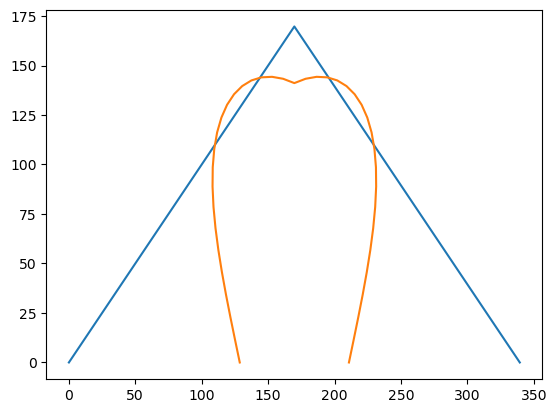

In [4]:
iters, nodes, DOF = a.shape

import matplotlib.pyplot as plt
fix, ax = plt.subplots()
stop = False
storeLR = []
for iter in range(iters):
    if iter * 11000 < iters:
        index = iter * 11000
    else :
        index = iters - 1
        stop = True
    ax.plot(a[index,:, 2], a[index,:,0])
    storeLR.append(b[index])
    if stop:
        break
print(np.array(storeLR) * 1_000) 
plt.show()


In [6]:
b

array([0.04      , 0.08      , 0.12      , ..., 0.4341662 , 0.43355795,
       0.432951  ], shape=(10999,))

In [7]:
import subprocess
from utilities import *
from solver import *

filename = 'inputSVQ04a'
directory = "input/SVQ_Cases"
subprocess.run(['python', f'{filename}.py'], cwd=directory, check=True)
modelingConditions, geometry, materialProperty, essentialBC, naturalBC, distributedForce, distributedMoment, followerLoad = inputJson()
classSVQ = SVQ(modelingConditions, geometry, materialProperty, essentialBC, naturalBC, distributedForce, distributedMoment, followerLoad)
    

In [8]:
classSVQ.prevConfig[:,2]

array([0.00000000e+00, 2.66453526e-15, 5.32907052e-15, 7.99360578e-15,
       1.06581410e-14, 1.33226763e-14, 1.59872116e-14, 1.86517468e-14,
       2.13162821e-14, 2.39808173e-14, 2.66453526e-14, 1.20000000e+01,
       2.40000000e+01, 3.60000000e+01, 4.80000000e+01, 6.00000000e+01,
       7.20000000e+01, 8.40000000e+01, 9.60000000e+01, 1.08000000e+02,
       1.20000000e+02])

In [12]:
import numpy as np
a = 1 / np.sqrt(2)
b = 2 * a
np.exp(0) / (2 * np.exp(a) + 1)

np.float64(0.1977758146404282)

In [14]:
0.248*2 + 0.504*2

1.504